# 01 Setup and inventory

Freeze the raw egocentric data and build an inventory with SHA-256 checksums.

## 1. Imports and tool check

Import the libraries and record the versions of python, the packages and ffmpeg.

In [1]:
import sys, os, platform, shutil, subprocess, json, re, hashlib, stat, zipfile
from datetime import datetime, timezone
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt
    import yaml
    import av
    import cv2
    from tqdm import tqdm
except ImportError as e:
    raise RuntimeError(f"missing package {e.name}, install it in the uv venv first") from None

RUN_TS = datetime.now(timezone.utc)

def tool_info(name):
    path = shutil.which(name)
    if path is None:
        return {"path": None, "version_line": None}
    try:
        r = subprocess.run([path, "-version"], capture_output=True, text=True, timeout=30)
        text = (r.stdout or r.stderr).strip()
        line = text.splitlines()[0] if text else "no version output"
    except Exception as e:
        line = f"version check failed: {e}"
    return {"path": path, "version_line": line}

env = {
    "run_utc": RUN_TS.isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "executable": sys.executable,
    "os": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "av": av.__version__,
    "cv2": cv2.__version__,
    "ffmpeg": tool_info("ffmpeg"),
    "ffprobe": tool_info("ffprobe"),
}

for k in ["python", "os", "numpy", "pandas", "av", "cv2"]:
    print(f"{k:8s} {env[k]}")
for t in ["ffmpeg", "ffprobe"]:
    if env[t]["path"]:
        print(f"{t:8s} {env[t]['version_line']}")
    else:
        print(f"{t:8s} NOT FOUND on PATH")
if env["ffprobe"]["path"] is None:
    print("warning: ffprobe is missing, the video checks in later notebooks need it")

python   3.13.13
os       Windows-11-10.0.26200-SP0
numpy    2.5.4
pandas   3.0.6
av       19.0.1
cv2      5.0.0
ffmpeg   ffmpeg version 9.0.2-full_build-www.gyan.dev Copyright (c) 2000-2026 the FFmpeg developers
ffprobe  ffprobe version 9.0.2-full_build-www.gyan.dev Copyright (c) 2007-2026 the FFmpeg developers


## 2. Config

Set the paths and the copy flag, then write configs/config.yaml if it is not there yet. An existing config is loaded and left alone.

In [2]:
SRC_ROOT = Path(r"C:\workstation\3RD YEAR\Egocenrtic")
PROJECT_ROOT = Path.cwd().resolve().parent
COPY_RAW = True

if Path.cwd().name.lower() != "notebooks":
    raise RuntimeError(f"working directory is {Path.cwd()}, it must be the notebooks folder")
if not SRC_ROOT.is_dir():
    raise RuntimeError(f"source folder not found: {SRC_ROOT}")
if PROJECT_ROOT.is_relative_to(SRC_ROOT.resolve()):
    raise RuntimeError("project root is inside the source folder, move the project somewhere else")
if SRC_ROOT.resolve().is_relative_to(PROJECT_ROOT / "raw"):
    raise RuntimeError("source folder is inside project raw folder, point SRC_ROOT at the original data")

CONFIG_PATH = PROJECT_ROOT / "configs" / "config.yaml"

default_cfg = {
    "source_root": str(SRC_ROOT),
    "directories": ["raw", "interim", "episodes", "mcap", "calib", "reports", "code", "configs", "notebooks"],
    "devices": {
        "head": {"folder": "head", "serial": "a45140", "camera_name": "cam_high"},
        "left": {"folder": "left", "serial": "a60617", "camera_name": "cam_left_wrist"},
        "right": {"folder": "right", "serial": "a59879", "camera_name": "cam_right_wrist"},
    },
    "nominal_fps": 30,
    "chunk_seconds_hypothesis": 180,
    "thresholds": {
        "freeze_run_frames": 5,
        "coverage_floor_pct": 30,
        "joint_conf_cutoff": 0.5,
        "min_joints": 15,
        "max_episode_sec": 1200,
        "pairing_tolerance_ms": 100,
    },
    "time": {
        "assumed_timezone": "Asia/Kolkata",
        "root_video_local_time": "2026-10-11T20:08:44",
    },
    "identity": {"vendor_name": "TBD", "operator_id": "TBD", "site": "TBD"},
}

CONFIG_PATH.parent.mkdir(parents=True, exist_ok=True)
if CONFIG_PATH.exists():
    cfg = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8")) or {}
    print("config already exists, loaded it")
else:
    cfg = default_cfg
    CONFIG_PATH.write_text(yaml.safe_dump(default_cfg, sort_keys=False), encoding="utf-8")
    print("config written")

missing_keys = [k for k in default_cfg if k not in cfg]
if missing_keys:
    raise RuntimeError(f"config.yaml is missing keys: {missing_keys}")
if str(cfg["source_root"]) != str(SRC_ROOT):
    print("note: source_root in config differs from SRC_ROOT, the notebook uses SRC_ROOT")

print("SRC_ROOT    ", SRC_ROOT)
print("PROJECT_ROOT", PROJECT_ROOT)
print("COPY_RAW    ", COPY_RAW)

config written
SRC_ROOT     C:\workstation\3RD YEAR\Egocenrtic
PROJECT_ROOT C:\workstation\3RD YEAR\ego_pipeline
COPY_RAW     True


## 3. Project folders

Create the project folders that are missing.

In [3]:
folder_names = list(dict.fromkeys(list(cfg["directories"]) + ["raw", "reports", "configs"]))
for name in folder_names:
    d = PROJECT_ROOT / name
    existed = d.is_dir()
    d.mkdir(parents=True, exist_ok=True)
    print("exists " if existed else "created", d)

RAW_DIR = PROJECT_ROOT / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
DEVS = list(cfg["devices"])

created C:\workstation\3RD YEAR\ego_pipeline\raw
created C:\workstation\3RD YEAR\ego_pipeline\interim
created C:\workstation\3RD YEAR\ego_pipeline\episodes
created C:\workstation\3RD YEAR\ego_pipeline\mcap
created C:\workstation\3RD YEAR\ego_pipeline\calib
exists  C:\workstation\3RD YEAR\ego_pipeline\reports
exists  C:\workstation\3RD YEAR\ego_pipeline\code
exists  C:\workstation\3RD YEAR\ego_pipeline\configs
exists  C:\workstation\3RD YEAR\ego_pipeline\notebooks


## 4. Pre-flight

Walk the source folder, count files and size, and check there is enough free disk space for the copy.

In [4]:
src_files = sorted(p for p in SRC_ROOT.rglob("*") if p.is_file())
if not src_files:
    raise RuntimeError(f"no files found under {SRC_ROOT}")

missing_dirs = [v["folder"] for v in cfg["devices"].values() if not (SRC_ROOT / v["folder"]).is_dir()]
if missing_dirs:
    raise RuntimeError(f"device folders not found in source: {missing_dirs}")

ext_counts = pd.Series([p.suffix.lower() or "(none)" for p in src_files]).value_counts()
total_bytes = sum(p.stat().st_size for p in src_files)
free_bytes = shutil.disk_usage(PROJECT_ROOT).free
free_disk_gb_before = round(free_bytes / 1e9, 2)

# bytes that still need copying, so a re-run is not blocked by its own earlier copies
todo_bytes = 0
for p in src_files:
    size = p.stat().st_size
    dst = RAW_DIR / p.relative_to(SRC_ROOT)
    if not (dst.is_file() and dst.stat().st_size == size):
        todo_bytes += size

print("files by extension:")
print(ext_counts.to_string())
print(f"total size {total_bytes / 1e9:.2f} GB, free on project drive {free_disk_gb_before} GB")

if COPY_RAW and free_bytes < 1.2 * todo_bytes:
    raise RuntimeError(
        f"free space {free_bytes / 1e9:.2f} GB is below 1.2 x {todo_bytes / 1e9:.2f} GB to copy, set COPY_RAW = False"
    )
print("disk space ok" if COPY_RAW else "COPY_RAW is False, no copy will be made")

files by extension:
.mp4    47
.txt    47
total size 7.82 GB, free on project drive 95.93 GB
disk space ok


## 5. Inventory

Build one row per file with the device, serial, clip number and timestamps parsed from the path. Files that do not fit the naming pattern are marked unrecognised.

In [5]:
NAME_RE = re.compile(
    r"^(?P<serial>[A-Za-z0-9]+)-H-(?P<clip>\d{4})(?P<dup>\(\d+\))?\.(?P<ext>mp4|txt)$", re.IGNORECASE
)
folder_to_dev = {v["folder"].lower(): k for k, v in cfg["devices"].items()}
serial_of = {k: v["serial"].lower() for k, v in cfg["devices"].items()}

def utc_iso(ts):
    return datetime.fromtimestamp(ts, tz=timezone.utc).isoformat(timespec="seconds")

def created_ts(st):
    if hasattr(st, "st_birthtime"):
        return st.st_birthtime
    return st.st_ctime

rows = []
for p in src_files:
    rel = p.relative_to(SRC_ROOT)
    st = p.stat()
    device = "root" if len(rel.parts) == 1 else folder_to_dev.get(rel.parts[0].lower(), "unknown")
    ext = p.suffix.lower()
    m = NAME_RE.match(p.name)
    serial, clip_no, dup = "", pd.NA, ""
    if m and device in cfg["devices"]:
        serial = m["serial"].lower()
        clip_no = int(m["clip"])
        dup = m["dup"] or ""
        kind = "video" if ext == ".mp4" else "imu"
    elif device == "root" and ext == ".mp4":
        kind = "root_video"
    else:
        kind = "unrecognised"
    rows.append({
        "rel_path": rel.as_posix(),
        "device": device,
        "serial": serial,
        "clip_no": clip_no,
        "dup_suffix": dup,
        "ext": ext,
        "kind": kind,
        "size_bytes": st.st_size,
        "src_modified_utc": utc_iso(st.st_mtime),
        "src_created_utc": utc_iso(created_ts(st)),
    })

inv = pd.DataFrame(rows)
inv["clip_no"] = inv["clip_no"].astype("Int64")

print(inv["kind"].value_counts().to_string())

unrec = inv[inv.kind == "unrecognised"]
if len(unrec):
    print(f"\n{len(unrec)} unrecognised files:")
    for r in unrec.rel_path.head(20):
        print("  ", r)
else:
    print("\nno unrecognised files")

recognised = inv[inv.kind.isin(["video", "imu"])]
bad_serial = recognised[recognised.serial != recognised.device.map(serial_of)]
if len(bad_serial):
    print(f"warning: {len(bad_serial)} files have a serial that does not match the device folder")

print()
print(inv[["rel_path", "device", "clip_no", "kind", "size_bytes"]].head(8).to_string(index=False))

kind
imu           47
video         46
root_video     1

no unrecognised files

                              rel_path device  clip_no  kind  size_bytes
head/VIDEO_CONVERTED/a45140-H-0036.mp4   head       36 video    92210659
head/VIDEO_CONVERTED/a45140-H-0036.txt   head       36   imu      507319
head/VIDEO_CONVERTED/a45140-H-0037.mp4   head       37 video   104136554
head/VIDEO_CONVERTED/a45140-H-0037.txt   head       37   imu      510678
head/VIDEO_CONVERTED/a45140-H-0038.mp4   head       38 video   104189759
head/VIDEO_CONVERTED/a45140-H-0038.txt   head       38   imu      511215
head/VIDEO_CONVERTED/a45140-H-0039.mp4   head       39 video   104138715
head/VIDEO_CONVERTED/a45140-H-0039.txt   head       39   imu      508829


## 6. Per-device clip table

For each device and clip number check which of the mp4 and txt files exist. Orphans, extra duplicates and gaps in the clip numbers are printed.

In [6]:
clips = inv[inv.kind.isin(["video", "imu"])]
if clips.empty:
    raise RuntimeError("no recognised clip files in the inventory")

rows = []
for (dev, no, dup), g in clips.groupby(["device", "clip_no", "dup_suffix"]):
    mp4 = g[g.ext == ".mp4"]
    txt = g[g.ext == ".txt"]
    has_mp4, has_txt = len(mp4) > 0, len(txt) > 0
    if dup:
        status = "duplicate_extra"
    elif has_mp4 and has_txt:
        status = "paired"
    elif has_txt:
        status = "txt_only"
    else:
        status = "mp4_only"
    rows.append({
        "device": dev,
        "clip_no": int(no),
        "dup_suffix": dup,
        "base_name": Path(g.rel_path.iloc[0]).stem,
        "has_mp4": has_mp4,
        "has_txt": has_txt,
        "mp4_size": int(mp4.size_bytes.iloc[0]) if has_mp4 else pd.NA,
        "txt_size": int(txt.size_bytes.iloc[0]) if has_txt else pd.NA,
        "status": status,
        "mp4_rel": mp4.rel_path.iloc[0] if has_mp4 else "",
        "txt_rel": txt.rel_path.iloc[0] if has_txt else "",
    })

by_device = pd.DataFrame(rows)
by_device["mp4_size"] = by_device["mp4_size"].astype("Int64")
by_device["txt_size"] = by_device["txt_size"].astype("Int64")
by_device["_order"] = by_device.device.map({d: i for i, d in enumerate(DEVS)})
by_device = by_device.sort_values(["_order", "clip_no", "dup_suffix"]).drop(columns="_order").reset_index(drop=True)

print(pd.crosstab(by_device.device, by_device.status).reindex(DEVS).to_string())

odd = by_device[by_device.status != "paired"]
print("\norphans and extras:")
if len(odd):
    print(odd[["device", "clip_no", "dup_suffix", "status", "base_name"]].head(20).to_string(index=False))
else:
    print("none")

print("\nclip number check:")
for dev in DEVS:
    nums = sorted(set(by_device[(by_device.device == dev) & (by_device.dup_suffix == "")].clip_no))
    if not nums:
        print(f"  {dev}: no clips")
        continue
    gaps = sorted(set(range(nums[0], nums[-1] + 1)) - set(nums))
    gap_text = "gaps at " + ", ".join(f"{g:04d}" for g in gaps) if gaps else "no gaps"
    print(f"  {dev}: {nums[0]:04d} to {nums[-1]:04d}, {gap_text}")

status  duplicate_extra  paired  txt_only
device                                   
head                  0      15         1
left                  1      15         0
right                 0      15         1

orphans and extras:
device  clip_no dup_suffix          status        base_name
  head       51                   txt_only    a45140-H-0051
  left       29        (1) duplicate_extra a60617-H-0029(1)
 right       41                   txt_only    a59879-H-0041

clip number check:
  head: 0036 to 0051, no gaps
  left: 0020 to 0034, no gaps
  right: 0026 to 0041, no gaps


## 7. Naive pairing preview

Line up the paired clips of each device by rank. This is only a first guess and it gets checked against timestamps later.

In [7]:
ranked = {}
for dev in DEVS:
    p = by_device[(by_device.device == dev) & (by_device.status == "paired")].sort_values("clip_no")
    ranked[dev] = p.base_name.reset_index(drop=True)

n_pairs = {d: len(s) for d, s in ranked.items()}
print("paired clips per device:", n_pairs)
if max(n_pairs.values()) == 0:
    raise RuntimeError("no paired clips on any device")
if len(set(n_pairs.values())) > 1:
    print("warning: paired clip counts differ, the extra ranks have empty cells")

naive = pd.DataFrame({"rank": range(1, max(n_pairs.values()) + 1)})
for dev in DEVS:
    naive[dev] = ranked[dev].reindex(range(len(naive))).values
naive["note"] = "naive by order, to be verified with timestamps in notebook 04"

print(naive.drop(columns="note").head(5).to_string(index=False))
print(f"... {len(naive)} ranks in total")

paired clips per device: {'head': 15, 'left': 15, 'right': 15}
 rank          head          left         right
    1 a45140-H-0036 a60617-H-0020 a59879-H-0026
    2 a45140-H-0037 a60617-H-0021 a59879-H-0027
    3 a45140-H-0038 a60617-H-0022 a59879-H-0028
    4 a45140-H-0039 a60617-H-0023 a59879-H-0029
    5 a45140-H-0040 a60617-H-0024 a59879-H-0030
... 15 ranks in total


## 8. Copy and hash

Read each source file once, hash it while copying it into raw, then hash the copy and compare. Copies that already match are skipped.

In [8]:
CHUNK = 8 * 1024 * 1024

manifest = inv.copy()
manifest["sha256"] = ""
manifest["copy_verified"] = False
manifest["read_only"] = False
manifest["data_path"] = ""

def hash_only(path, bar):
    h = hashlib.sha256()
    n = 0
    with open(path, "rb") as f:
        while True:
            b = f.read(CHUNK)
            if not b:
                break
            h.update(b)
            n += len(b)
            bar.update(len(b))
    return h.hexdigest(), n

def copy_and_hash(src, dst, bar):
    h = hashlib.sha256()
    n = 0
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp = dst.with_name(dst.name + ".part")
    with open(src, "rb") as fi, open(tmp, "wb") as fo:
        while True:
            b = fi.read(CHUNK)
            if not b:
                break
            h.update(b)
            fo.write(b)
            n += len(b)
            bar.update(len(b))
    if dst.exists():
        os.chmod(dst, stat.S_IREAD | stat.S_IWRITE)
    os.replace(tmp, dst)
    return h.hexdigest(), n

n_copied = n_skipped = 0
passes = 2 if COPY_RAW else 1
bar_total = int(manifest.size_bytes.sum()) * passes

with tqdm(total=bar_total, unit="B", unit_scale=True, unit_divisor=1024, desc="hash and copy") as bar:
    for i, row in manifest.iterrows():
        src = SRC_ROOT / row.rel_path
        size = int(row.size_bytes)

        if not COPY_RAW:
            sha, n = hash_only(src, bar)
            if n != size:
                raise RuntimeError(f"size changed while reading {row.rel_path}")
            manifest.at[i, "sha256"] = sha
            manifest.at[i, "data_path"] = str(src)
            continue

        dst = RAW_DIR / row.rel_path
        done = False
        if dst.is_file() and dst.stat().st_size == size:
            sha, n = hash_only(src, bar)
            dsha, _ = hash_only(dst, bar)
            if n != size:
                raise RuntimeError(f"size changed while reading {row.rel_path}")
            if sha == dsha:
                n_skipped += 1
                done = True
            else:
                bar.total += 2 * size
                bar.refresh()

        if not done:
            sha, n = copy_and_hash(src, dst, bar)
            if n != size:
                raise RuntimeError(f"size changed while reading {row.rel_path}")
            vsha, _ = hash_only(dst, bar)
            if vsha != sha or dst.stat().st_size != size:
                raise RuntimeError(f"copy does not match source: {row.rel_path}")
            n_copied += 1

        manifest.at[i, "sha256"] = sha
        manifest.at[i, "copy_verified"] = True
        manifest.at[i, "data_path"] = str(dst)

if COPY_RAW:
    print(f"copied {n_copied}, skipped {n_skipped} already verified, {len(manifest)} files in total")
else:
    print(f"hashed {len(manifest)} source files, nothing copied")

hash and copy: 100%|██████████| 14.6G/14.6G [01:01<00:00, 256MB/s] 

copied 94, skipped 0 already verified, 94 files in total


## 9. Read-only copies

Set the copied files to read-only and check with os.access that none of them can be written.

In [9]:
if COPY_RAW:
    for rel in manifest.rel_path:
        os.chmod(RAW_DIR / rel, stat.S_IREAD)
    manifest["read_only"] = [not os.access(RAW_DIR / rel, os.W_OK) for rel in manifest.rel_path]
    still_writable = manifest[~manifest.read_only]
    if len(still_writable):
        raise RuntimeError(f"{len(still_writable)} copies are still writable, first: {still_writable.rel_path.iloc[0]}")
    print(f"all {len(manifest)} copies are read-only")
else:
    print("COPY_RAW is False, there are no copies to lock")

all 94 copies are read-only


## 10. Duplicate analysis

Group the files by hash, flag empty files and compare each extra duplicate with its original.

In [10]:
dup_cols = ["issue", "group_id", "rel_path", "size_bytes", "sha256", "src_modified_utc"]
parts = []

same = manifest.groupby("sha256").filter(lambda g: len(g) > 1).copy()
if len(same):
    same["group_id"] = same.groupby("sha256").ngroup() + 1
    same["issue"] = "same_hash"
    parts.append(same[dup_cols])
n_groups = int(same["group_id"].nunique()) if len(same) else 0
print(f"hash groups with more than one file: {n_groups}")
if n_groups:
    g_sizes = same.groupby("group_id").agg(files=("rel_path", "size"), size_bytes=("size_bytes", "first"))
    print(g_sizes.head(10).to_string())

zero = manifest[manifest.size_bytes == 0].copy()
print(f"zero-byte files: {len(zero)}")
if len(zero):
    zero["issue"] = "zero_byte"
    zero["group_id"] = pd.NA
    parts.append(zero[dup_cols])
    for r in zero.rel_path.head(20):
        print("  ", r)

extras = manifest[manifest.dup_suffix != ""].copy()
compare = []
for _, e in extras.iterrows():
    base = manifest[
        (manifest.device == e.device) & (manifest.clip_no == e.clip_no)
        & (manifest.ext == e.ext) & (manifest.dup_suffix == "")
    ]
    if base.empty:
        print(f"{e.rel_path}: no original file found")
        compare.append({"extra": e.rel_path, "original": None})
        continue
    b = base.iloc[0]
    info = {
        "extra": e.rel_path,
        "original": b.rel_path,
        "extra_size": int(e.size_bytes),
        "original_size": int(b.size_bytes),
        "same_size": bool(e.size_bytes == b.size_bytes),
        "same_sha256": bool(e.sha256 == b.sha256),
        "extra_modified_utc": e.src_modified_utc,
        "original_modified_utc": b.src_modified_utc,
    }
    compare.append(info)
    print(f"\n{Path(e.rel_path).name} vs {Path(b.rel_path).name}")
    print(f"  size      {info['extra_size']} vs {info['original_size']}")
    print(f"  sha256    {'equal' if info['same_sha256'] else 'different'}")
    print(f"  modified  {info['extra_modified_utc']} vs {info['original_modified_utc']}")
if extras.empty:
    print("no extra duplicate files")

if len(extras):
    ex = extras.copy()
    ex["issue"] = "duplicate_extra"
    ex["group_id"] = pd.NA
    parts.append(ex[dup_cols])

dup_table = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=dup_cols)

hash groups with more than one file: 1
          files  size_bytes
group_id                   
1             2   104825592
zero-byte files: 0

a60617-H-0029(1).mp4 vs a60617-H-0029.mp4
  size      104825592 vs 104825592
  sha256    equal
  modified  2026-10-12T05:26:43+00:00 vs 2026-10-12T05:26:33+00:00


## 11. File size figure

Plot the mp4 size and the txt size for every clip rank, one line per device.

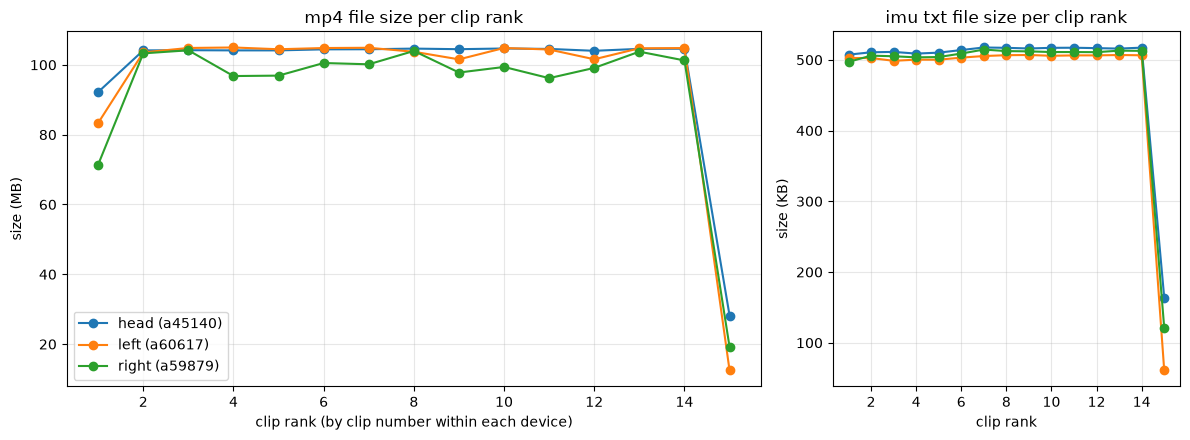

saved C:\workstation\3RD YEAR\ego_pipeline\reports\01_file_sizes.png


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for dev in DEVS:
    d = by_device[(by_device.device == dev) & (by_device.status == "paired")].sort_values("clip_no")
    x = np.arange(1, len(d) + 1)
    label = f"{dev} ({cfg['devices'][dev]['serial']})"
    ax1.plot(x, d.mp4_size.astype(float) / 1e6, marker="o", label=label)
    ax2.plot(x, d.txt_size.astype(float) / 1e3, marker="o", label=label)

ax1.set_title("mp4 file size per clip rank")
ax1.set_xlabel("clip rank (by clip number within each device)")
ax1.set_ylabel("size (MB)")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.set_title("imu txt file size per clip rank")
ax2.set_xlabel("clip rank")
ax2.set_ylabel("size (KB)")
ax2.grid(alpha=0.3)

fig.tight_layout()
fig_path = REPORTS_DIR / "01_file_sizes.png"
fig.savefig(fig_path, dpi=150)
plt.show()
plt.close(fig)
print("saved", fig_path)

## 12. Save outputs

Write the manifest, tables and summary files into reports.

In [12]:
manifest_cols = [
    "rel_path", "device", "serial", "clip_no", "dup_suffix", "kind", "size_bytes",
    "sha256", "src_modified_utc", "src_created_utc", "copy_verified", "read_only",
]
manifest[manifest_cols].to_csv(REPORTS_DIR / "raw_manifest.csv", index=False)
by_device.to_csv(REPORTS_DIR / "01_inventory_by_device.csv", index=False)
naive.to_csv(REPORTS_DIR / "01_naive_pairing.csv", index=False)
dup_table.to_csv(REPORTS_DIR / "01_duplicates.csv", index=False)

with open(REPORTS_DIR / "01_environment.json", "w", encoding="utf-8") as f:
    json.dump(env, f, indent=2)

summary = {
    "run_timestamp_utc": RUN_TS.isoformat(timespec="seconds"),
    "copy_raw": COPY_RAW,
    "file_count": int(len(manifest)),
    "counts_per_kind": {k: int(v) for k, v in inv.kind.value_counts().items()},
    "total_bytes": int(manifest.size_bytes.sum()),
    "orphan_txt_files": by_device[by_device.status == "txt_only"].txt_rel.tolist(),
    "orphan_mp4_files": by_device[by_device.status == "mp4_only"].mp4_rel.tolist(),
    "duplicate_extras": extras.rel_path.tolist(),
    "unrecognised_files": unrec.rel_path.tolist(),
    "zero_byte_files": zero.rel_path.tolist(),
    "all_hashes_verified": bool(manifest.copy_verified.all()),
    "all_read_only": bool(manifest.read_only.all()),
    "free_disk_gb_before": float(free_disk_gb_before),
    "ffprobe_found": env["ffprobe"]["path"] is not None,
    "duplicate_extra_compare": compare,
}
with open(REPORTS_DIR / "01_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

out_names = [
    "raw_manifest.csv", "01_inventory_by_device.csv", "01_naive_pairing.csv", "01_duplicates.csv",
    "01_environment.json", "01_summary.json", "01_file_sizes.png",
]
for n in out_names:
    if not (REPORTS_DIR / n).is_file():
        raise RuntimeError(f"output missing: {n}")
print("saved", len(out_names), "files in", REPORTS_DIR)

saved 7 files in C:\workstation\3RD YEAR\ego_pipeline\reports


## 13. Share zip and summary

Put the output files into one zip and print a short summary of the run.

In [13]:
zip_path = REPORTS_DIR / "share_01.zip"
tmp_zip = REPORTS_DIR / "share_01.zip.tmp"
with zipfile.ZipFile(tmp_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for n in out_names:
        z.write(REPORTS_DIR / n, arcname=n)
os.replace(tmp_zip, zip_path)

kinds = ", ".join(f"{k} {v}" for k, v in summary["counts_per_kind"].items())
if COPY_RAW:
    check = "all copies match the source hash" if summary["all_hashes_verified"] else "NOT all copies verified"
    lock = "all read-only" if summary["all_read_only"] else "NOT all read-only"
else:
    check = "no copy made, source files hashed only"
    lock = "not applicable"

print(f"files: {summary['file_count']} ({kinds})")
print(f"total size: {summary['total_bytes'] / 1e9:.2f} GB")
print(f"orphan txt: {len(summary['orphan_txt_files'])}, orphan mp4: {len(summary['orphan_mp4_files'])}")
print(f"duplicate extras: {len(summary['duplicate_extras'])}, zero-byte files: {len(summary['zero_byte_files'])}")
print(f"verification: {check}; raw copies {lock}")
print(f"ffmpeg found: {env['ffmpeg']['path'] is not None}, ffprobe found: {summary['ffprobe_found']}")
print(f"zip: {zip_path}")

files: 94 (imu 47, video 46, root_video 1)
total size: 7.82 GB
orphan txt: 2, orphan mp4: 0
duplicate extras: 1, zero-byte files: 0
verification: all copies match the source hash; raw copies all read-only
ffmpeg found: True, ffprobe found: True
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_01.zip
